# When does first-order variance propagation hold?

Scipp versus Monte Carlo, and what `es.math` adds, on the `add-maths-module` branch.

**Question.** Scipp propagates the variance of a result to first order,
$$\operatorname{var}(f)=\sum_i\left(\frac{\partial f}{\partial x_i}\right)^2\operatorname{var}(x_i),$$
and treats the inputs as independent. `es.math` and the `Parameter` operators build on it. When is
that right, and when is it not?

**The comparisons, in this order**

| Step | Compares | Why |
|---|---|---|
| **A** | Scipp against Monte Carlo | **The main question**: is the first-order variance correct? |
| **B** | `es.math` against Scipp | Secondary: does `es.math` add or change anything? |
| **C** | all three together | Overview of A and B |

Part 1 uses one input without correlation (1A, 1B, 1C); Part 2 uses two correlated inputs
(2A, 2B, 2C).

**Ground truth.** A Monte Carlo sample of 2,000,000 draws (noise about 0.14 %). A ratio is the
library variance divided by the Monte Carlo variance; a case *holds* when it is within 5 %.

**Scipp's coverage.** Scipp 26.7.0 propagates variances through `sin`, `cos`, `tan`, the inverse
and hyperbolic functions, `exp`, `log`, `log10`, `sqrt`, `sinc` and the arithmetic operators. It
raises `VariancesError` for `erf`, `erfc` and `atan2`, so those have no Scipp column below.

## Summary of the findings

| Situation | Scipp against Monte Carlo |
|---|---|
| Small $\sigma$, smooth function, independent inputs | **Holds** (within 0.6 %) |
| Large $\sigma$ relative to the curvature (`exp`, `log`, `sqrt`) | **Fails**: `exp` with $\sigma=1$ is about 5x too small |
| Derivative is zero (`sin` at its maximum, `cosh` at 0) | **Fails**: the formula gives 0, the true variance is of order $\sigma^4/2$ |
| Close to a pole (`tan`) | **Fails**: the true variance is infinite |
| Correlated inputs with `a - b`, `a + b`, `a / b` | **Fails** by factors of 0.5 to 20 |
| Correlated inputs, but one $\sigma$ is negligible | **Holds** |
| Correlated inputs with large $\sigma$ and a product | Fails even with the covariance |

`es.math` gives the same variance as Scipp wherever Scipp has one (1B, 2B), so these are the limits
of first-order propagation itself, not of `es.math`. `es.math` additionally covers `erf`, `erfc`
and `arctan2`.

In [9]:
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipp as sc
from scipy.special import erf as scipy_erf

import easyscience as es
from easyscience import Parameter
from easyscience import math as m

repo = Path(es.__file__).resolve().parents[2]
branch = subprocess.run(
    ['git', '-C', str(repo), 'rev-parse', '--abbrev-ref', 'HEAD'],
    capture_output=True,
    text=True,
).stdout.strip()
commit = subprocess.run(
    ['git', '-C', str(repo), 'rev-parse', '--short', 'HEAD'],
    capture_output=True,
    text=True,
).stdout.strip()
print(f'code under test: branch {branch!r} at {commit}; scipp {sc.__version__}')

N = 2_000_000
HOLDS_WITHIN = 0.05
plt.rcParams['figure.dpi'] = 110

code under test: branch 'add-maths-module' at 3bff5f3; scipp 26.7.0


## Helpers

Each library is called through one small function, so the three columns are computed the same way:

* `scipp_variance(function, *scalars)`: a Scipp scalar with variance $\sigma^2$ goes in. If Scipp
  raises (`VariancesError`), the result is `None`, shown as *n/a*.
* `es_variance(function, *parameters)`: the same for a `Parameter` (the library under test).
* `monte_carlo_variance(function, *samples)`: the ground truth. Samples that leave a function's
  domain (a `NaN`) are dropped, which is noted where it applies.
* `full_covariance_variance`: the first-order variance with the covariance, $\mathbf g^{\mathsf T} C\,\mathbf g$,
  used only as a labelled *reference* in Part 2.

In [10]:
def scipp_scalar(value, sigma, unit=''):
    return sc.scalar(float(value), variance=float(sigma) ** 2, unit=unit or 'dimensionless')


def parameter(value, sigma, unit=''):
    return Parameter('x', value, variance=sigma**2, unit=unit)


def scipp_variance(function, *scalars):
    try:
        return float(function(*scalars).variance)
    except Exception:  # scipp.VariancesError: no variance propagation for this function
        return None


def es_variance(function, *parameters):
    try:
        variance = function(*parameters).variance
        return 0.0 if variance is None else float(variance)
    except Exception:  # a guard of es.math refused the input
        return None


def monte_carlo_variance(function, *samples):
    with np.errstate(all='ignore'):
        values = function(*samples)
    return float(np.var(values[np.isfinite(values)]))


def numerical_gradient(function, mean, relative_step=1e-6):
    mean = np.asarray(mean, dtype=float)
    gradient = np.zeros_like(mean)
    for i in range(len(mean)):
        step = np.zeros_like(mean)
        step[i] = relative_step * max(abs(mean[i]), 1e-3)
        gradient[i] = (function(*(mean + step)) - function(*(mean - step))) / (2 * step[i])
    return gradient


def full_covariance_variance(function, mean, covariance):
    gradient = numerical_gradient(function, mean)
    return float(gradient @ covariance @ gradient)


def verdict(library, truth):
    if library is None:
        return 'n/a'
    return 'holds' if abs(library / truth - 1) < HOLDS_WITHIN else 'FAILS'


def number(value):
    return 'n/a' if value is None else f'{value:.4g}'


def ratio(library, truth):
    return 'n/a' if library is None else f'{library / truth:.3f}'


def table(rows, columns):
    return pd.DataFrame(rows, columns=columns).style.hide(axis='index')

# Part 1: one input, no correlation

Each case draws $x\sim\mathcal N(\text{mean},\sigma^2)$ and applies the function. The same twelve
cases are used in 1A, 1B and 1C.

In [11]:
rng = np.random.default_rng(20261013)

single_cases = [
    # label, scipp function, es.math function, numpy function, mean, sigma, unit
    ('sin   x=1.0   sigma=0.02', sc.sin, m.sin, np.sin, 1.0, 0.02, 'rad'),
    ('exp   x=1.0   sigma=0.05', sc.exp, m.exp, np.exp, 1.0, 0.05, ''),
    ('log   x=10    sigma=0.1', sc.log, m.log, np.log, 10.0, 0.1, ''),
    ('sqrt  x=4     sigma=0.1', sc.sqrt, m.sqrt, np.sqrt, 4.0, 0.1, ''),
    ('erf   x=0.5   sigma=0.05', sc.erf, m.erf, scipy_erf, 0.5, 0.05, ''),
    ('tanh  x=0.5   sigma=0.05', sc.tanh, m.tanh, np.tanh, 0.5, 0.05, ''),
    ('exp   x=1.0   sigma=1.0   (large sigma)', sc.exp, m.exp, np.exp, 1.0, 1.0, ''),
    ('log   x=3     sigma=0.9   (large sigma)', sc.log, m.log, np.log, 3.0, 0.9, ''),
    (
        'sqrt  x=1     sigma=0.4   (large sigma, 0.6 % dropped)',
        sc.sqrt,
        m.sqrt,
        np.sqrt,
        1.0,
        0.4,
        '',
    ),
    ('sin   x=pi/2  sigma=0.3   (at a maximum)', sc.sin, m.sin, np.sin, np.pi / 2, 0.3, 'rad'),
    ('cosh  x=0     sigma=0.5   (at a minimum)', sc.cosh, m.cosh, np.cosh, 0.0, 0.5, ''),
    (
        'tan   x=1.5   sigma=0.05  (1.4 sigma from the pole)',
        sc.tan,
        m.tan,
        np.tan,
        1.5,
        0.05,
        'rad',
    ),
]

part1 = []
for label, scipp_function, es_function, np_function, mean, sigma, unit in single_cases:
    part1.append({
        'case': label,
        'scipp': scipp_variance(scipp_function, scipp_scalar(mean, sigma, unit)),
        'es': es_variance(es_function, parameter(mean, sigma, unit)),
        'mc': monte_carlo_variance(np_function, rng.normal(mean, sigma, N)),
    })
print(f'{len(part1)} cases computed with Scipp, es.math and Monte Carlo')

12 cases computed with Scipp, es.math and Monte Carlo


## 1A. Scipp against Monte Carlo

**This is the main comparison.** `Scipp/MC` is Scipp's first-order variance divided by the Monte
Carlo variance.

In [12]:
table(
    [
        (
            r['case'],
            number(r['scipp']),
            number(r['mc']),
            ratio(r['scipp'], r['mc']),
            verdict(r['scipp'], r['mc']),
        )
        for r in part1
    ],
    ['case', 'Scipp', 'Monte Carlo', 'Scipp/MC', 'verdict'],
)

case,Scipp,Monte Carlo,Scipp/MC,verdict
sin x=1.0 sigma=0.02,0.0001168,0.0001168,1.000,holds
exp x=1.0 sigma=0.05,0.01847,0.01857,0.995,holds
log x=10 sigma=0.1,0.0001,0.0001002,0.998,holds
sqrt x=4 sigma=0.1,0.000625,0.0006245,1.001,holds
erf x=0.5 sigma=0.05,n/a,0.001931,n/a,n/a
tanh x=0.5 sigma=0.05,0.001546,0.001544,1.002,holds
exp x=1.0 sigma=1.0 (large sigma),7.389,34.42,0.215,FAILS
log x=3 sigma=0.9 (large sigma),0.09,0.1258,0.715,FAILS
"sqrt x=1 sigma=0.4 (large sigma, 0.6 % dropped)",0.04,0.04414,0.906,FAILS
sin x=pi/2 sigma=0.3 (at a maximum),3.374e-34,0.003714,0.000,FAILS


**Reading the table.** With small $\sigma$ Scipp agrees with Monte Carlo to within 0.6 %. `erf` has
no Scipp value (Scipp cannot propagate a variance through it). The failures fall into three groups,
shown in the plots below: large $\sigma$, a zero derivative, and a pole.

### 1A-1. How fast does it break down as $\sigma$ grows?

`Scipp/MC` against the *relative* $\sigma$, $\sigma/\lvert\text{mean}\rvert$ (the means are 1 for `exp`,
3 for `log` and `sqrt`). The shaded band is the 5 % tolerance.

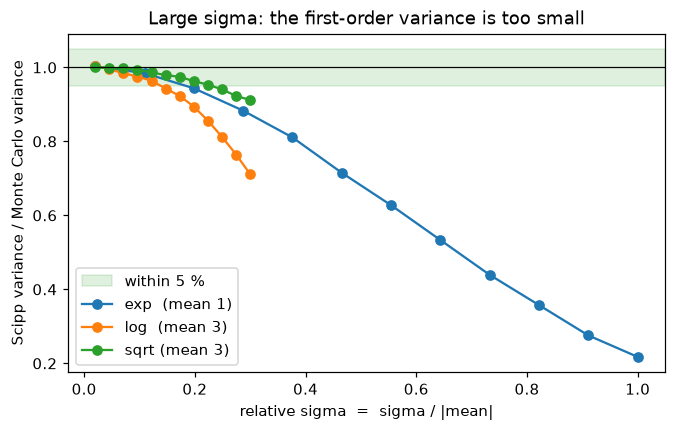

In [13]:
rng = np.random.default_rng(1)
sweeps = {
    'exp  (mean 1)': (sc.exp, np.exp, 1.0, np.linspace(0.02, 1.0, 12)),
    'log  (mean 3)': (sc.log, np.log, 3.0, np.linspace(0.02, 0.3, 12) * 3.0),
    'sqrt (mean 3)': (sc.sqrt, np.sqrt, 3.0, np.linspace(0.02, 0.3, 12) * 3.0),
}
fig, ax = plt.subplots(figsize=(7, 4))
ax.axhspan(1 - HOLDS_WITHIN, 1 + HOLDS_WITHIN, color='tab:green', alpha=0.15, label='within 5 %')
for name, (scipp_function, np_function, mean, sigmas) in sweeps.items():
    ratios = []
    for sigma in sigmas:
        truth = monte_carlo_variance(np_function, rng.normal(mean, sigma, 500_000))
        ratios.append(scipp_variance(scipp_function, scipp_scalar(mean, sigma)) / truth)
    ax.plot(sigmas / mean, ratios, 'o-', label=name)
ax.axhline(1.0, color='k', lw=0.8)
ax.set_xlabel('relative sigma  =  sigma / |mean|')
ax.set_ylabel('Scipp variance / Monte Carlo variance')
ax.set_title('Large sigma: the first-order variance is too small')
ax.legend()
plt.show()

### 1A-2. A zero derivative: `sin` at its maximum

At $x=\pi/2$ the derivative is $\cos x=0$, so the first-order formula returns 0. The real variance
is of order $\sigma^4/2$ because only the curvature contributes.

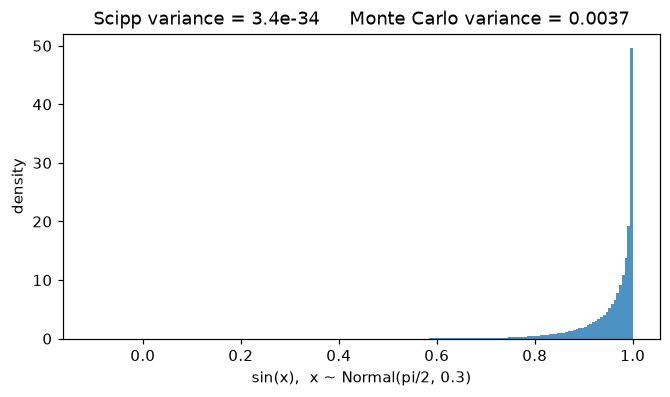

sigma^4 / 2 = 0.0040  (the leading term of the true variance)


In [14]:
rng = np.random.default_rng(2)
mean, sigma = np.pi / 2, 0.3
samples = np.sin(rng.normal(mean, sigma, N))
library = scipp_variance(sc.sin, scipp_scalar(mean, sigma, 'rad'))
truth = float(np.var(samples))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(samples, bins=200, density=True, color='tab:blue', alpha=0.8)
ax.set_xlabel('sin(x),  x ~ Normal(pi/2, 0.3)')
ax.set_ylabel('density')
ax.set_title(f'Scipp variance = {library:.2g}     Monte Carlo variance = {truth:.4f}')
plt.show()
print(f'sigma^4 / 2 = {sigma**4 / 2:.4f}  (the leading term of the true variance)')

### 1A-3. Near a pole: `tan`

At $x=1.5$ the pole at $\pi/2$ is only $1.4\,\sigma$ away, so about 8 % of the samples are on the other
side of it. The true variance is infinite, and the Monte Carlo value below is an artefact of a handful
of huge samples. Scipp has no guard, so it returns a finite number that means nothing.

In [15]:
rng = np.random.default_rng(3)
mean, sigma = 1.5, 0.05
crossing = float(np.mean(rng.normal(mean, sigma, N) > np.pi / 2))
print(f'fraction of samples beyond the pole: {crossing:.1%}')
print(f'Scipp variance:   {scipp_variance(sc.tan, scipp_scalar(mean, sigma, "rad")):.4g}')
for repeat in range(3):
    chunk = rng.normal(mean, sigma, N)
    print(f'Monte Carlo variance, independent run {repeat + 1}: {np.var(np.tan(chunk)):.3g}')

fraction of samples beyond the pole: 7.8%
Scipp variance:   99.85
Monte Carlo variance, independent run 1: 1.83e+08
Monte Carlo variance, independent run 2: 7.36e+07
Monte Carlo variance, independent run 3: 4.72e+09


The three independent Monte Carlo runs disagree by orders of magnitude, which is the signature of an
infinite variance. Treat any first-order variance within a few $\sigma$ of a pole as unreliable.

## 1B. `es.math` against Scipp

**Secondary comparison.** Does `es.math` change the variance that Scipp gives? `es/Scipp` is the
`es.math` variance divided by the Scipp variance; *agree* means equal to within rounding
($10^{-6}$ relative, $10^{-12}$ absolute).

In [16]:
def agreement(es_value, scipp_value):
    if scipp_value is None:
        return 'Scipp n/a'
    if es_value is None:
        return 'es.math refused'
    return 'agree' if np.isclose(es_value, scipp_value, rtol=1e-6, atol=1e-12) else 'DIFFER'


def ratio_to_scipp(es_value, scipp_value):
    if es_value is None or scipp_value is None or scipp_value < 1e-12:
        return 'n/a'
    return f'{es_value / scipp_value:.6f}'


table(
    [
        (
            r['case'],
            number(r['scipp']),
            number(r['es']),
            ratio_to_scipp(r['es'], r['scipp']),
            agreement(r['es'], r['scipp']),
        )
        for r in part1
    ],
    ['case', 'Scipp', 'es.math', 'es/Scipp', 'result'],
)

case,Scipp,es.math,es/Scipp,result
sin x=1.0 sigma=0.02,0.0001168,0.0001168,1.000000,agree
exp x=1.0 sigma=0.05,0.01847,0.01847,1.000000,agree
log x=10 sigma=0.1,0.0001,0.0001,1.000000,agree
sqrt x=4 sigma=0.1,0.000625,0.000625,1.000000,agree
erf x=0.5 sigma=0.05,n/a,0.001931,n/a,Scipp n/a
tanh x=0.5 sigma=0.05,0.001546,0.001546,1.000000,agree
exp x=1.0 sigma=1.0 (large sigma),7.389,7.389,1.000000,agree
log x=3 sigma=0.9 (large sigma),0.09,0.09,1.000000,agree
"sqrt x=1 sigma=0.4 (large sigma, 0.6 % dropped)",0.04,0.04,1.000000,agree
sin x=pi/2 sigma=0.3 (at a maximum),3.374e-34,3.374e-34,n/a,agree


**Reading the table.** Wherever Scipp has a variance, `es.math` returns the same number to
rounding: it calls Scipp for the value and the variance. The two cases where the values are around
$10^{-34}$ or exactly 0 are the zero-derivative cases, where both are zero. The only difference is
coverage: `erf` has an `es.math` variance (from its own derivative) and no Scipp one.

## 1C. All three together

`Scipp/MC` and `es/MC` side by side, with the 5 % band. Because the library columns coincide, the
answer to "does `es.math` hold?" is the answer to "does Scipp hold?".

In [17]:
table(
    [
        (
            r['case'],
            number(r['scipp']),
            number(r['es']),
            number(r['mc']),
            ratio(r['scipp'], r['mc']),
            ratio(r['es'], r['mc']),
        )
        for r in part1
    ],
    ['case', 'Scipp', 'es.math', 'Monte Carlo', 'Scipp/MC', 'es/MC'],
)

case,Scipp,es.math,Monte Carlo,Scipp/MC,es/MC
sin x=1.0 sigma=0.02,0.0001168,0.0001168,0.0001168,1.000,1.000
exp x=1.0 sigma=0.05,0.01847,0.01847,0.01857,0.995,0.995
log x=10 sigma=0.1,0.0001,0.0001,0.0001002,0.998,0.998
sqrt x=4 sigma=0.1,0.000625,0.000625,0.0006245,1.001,1.001
erf x=0.5 sigma=0.05,n/a,0.001931,0.001931,n/a,1.000
tanh x=0.5 sigma=0.05,0.001546,0.001546,0.001544,1.002,1.002
exp x=1.0 sigma=1.0 (large sigma),7.389,7.389,34.42,0.215,0.215
log x=3 sigma=0.9 (large sigma),0.09,0.09,0.1258,0.715,0.715
"sqrt x=1 sigma=0.4 (large sigma, 0.6 % dropped)",0.04,0.04,0.04414,0.906,0.906
sin x=pi/2 sigma=0.3 (at a maximum),3.374e-34,3.374e-34,0.003714,0.000,0.000


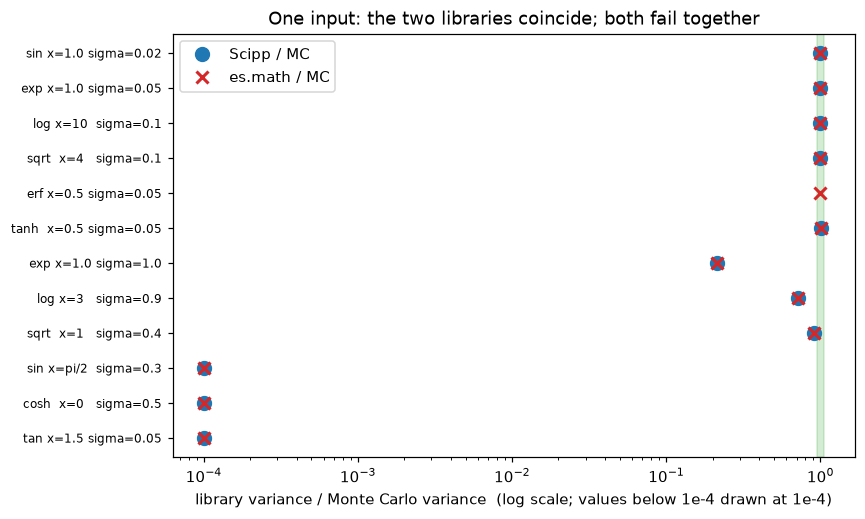

In [18]:
labels = [r['case'].split('  (')[0].replace('   ', ' ').strip() for r in part1]
floor = 1e-4
scipp_ratio = [np.nan if r['scipp'] is None else max(r['scipp'] / r['mc'], floor) for r in part1]
es_ratio = [np.nan if r['es'] is None else max(r['es'] / r['mc'], floor) for r in part1]
position = np.arange(len(part1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.axvspan(1 - HOLDS_WITHIN, 1 + HOLDS_WITHIN, color='tab:green', alpha=0.2)
ax.plot(scipp_ratio, position, 'o', color='tab:blue', ms=9, label='Scipp / MC')
ax.plot(es_ratio, position, 'x', color='tab:red', ms=8, mew=2, label='es.math / MC')
ax.set_xscale('log')
ax.set_yticks(position)
ax.set_yticklabels(labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel(
    'library variance / Monte Carlo variance  (log scale; values below 1e-4 drawn at 1e-4)'
)
ax.set_title('One input: the two libraries coincide; both fail together')
ax.legend(loc='upper left')
plt.show()

**Reading the figure.** The blue circles and red crosses sit on top of each other: the same
variance, the same failures. The rows at the left edge are the zero-derivative and pole cases. The
`erf` row has only the red cross, because only `es.math` can produce a value.

# Part 2: two inputs with a correlation

The inputs $(a,b)$ are drawn from a bivariate normal with correlation $\rho$. **Neither Scipp nor
`es.math` has any notion of $\rho$**: the variances of `a - b`, `a + b`, `a / b`, `a * b` and
`arctan2` treat the two inputs as independent. This part measures what that costs.

The operators are the same lambdas for Scipp, for `Parameter` and for NumPy. `arctan2` has no Scipp
variance, so it appears only where `es.math` is involved (2B, 2C). The *reference* column,
$\mathbf g^{\mathsf T} C\,\mathbf g$, is the first-order variance *with* the covariance; it is not part of
either library, and shows whether a failure comes from the correlation or from non-linearity.

In [19]:
rng = np.random.default_rng(20261014)

sub = lambda a, b: a - b
add = lambda a, b: a + b
div = lambda a, b: a / b
mul = lambda a, b: a * b
scipp_atan2 = lambda y, x: sc.atan2(y=y, x=x)

# key, label, scipp function, es function, numpy function, mean, sigma, rho values
two_input_cases = [
    (
        'sub',
        'a - b      a=5, b=4   sigma .1, .1',
        sub,
        sub,
        sub,
        (5.0, 4.0),
        (0.1, 0.1),
        (0.0, 0.9, -0.9),
    ),
    (
        'add',
        'a + b      a=5, b=4   sigma .1, .1',
        add,
        add,
        add,
        (5.0, 4.0),
        (0.1, 0.1),
        (0.0, -0.9),
    ),
    (
        'add_tiny',
        'a + b      sigma .1, .001  (b negligible)',
        add,
        add,
        add,
        (5.0, 4.0),
        (0.1, 0.001),
        (0.9,),
    ),
    ('div', 'a / b      a=b=10   sigma .5', div, div, div, (10.0, 10.0), (0.5, 0.5), (0.95,)),
    (
        'mul',
        'a * b      a=b=1    sigma .5  (large sigma)',
        mul,
        mul,
        mul,
        (1.0, 1.0),
        (0.5, 0.5),
        (-0.5,),
    ),
    (
        'atan2',
        'arctan2(a, b)  a=1, b=2   sigma .1, .1',
        scipp_atan2,
        m.arctan2,
        np.arctan2,
        (1.0, 2.0),
        (0.1, 0.1),
        (0.0, -0.87, 0.87),
    ),
    (
        'atan2_flat',
        'arctan2(a, b)  a=0, b=2   sigma .05  (d/db = 0)',
        scipp_atan2,
        m.arctan2,
        np.arctan2,
        (0.0, 2.0),
        (0.05, 0.05),
        (0.9,),
    ),
]

part2 = []
for key, label, scipp_function, es_function, np_function, mean, sigma, rhos in two_input_cases:
    for rho in rhos:
        covariance = np.array([
            [sigma[0] ** 2, rho * sigma[0] * sigma[1]],
            [rho * sigma[0] * sigma[1], sigma[1] ** 2],
        ])
        samples = rng.multivariate_normal(mean, covariance, N)
        part2.append({
            'key': key,
            'case': f'{label}   rho={rho:+.2f}',
            'rho': rho,
            'scipp': scipp_variance(
                scipp_function, scipp_scalar(mean[0], sigma[0]), scipp_scalar(mean[1], sigma[1])
            ),
            'es': es_variance(
                es_function, parameter(mean[0], sigma[0]), parameter(mean[1], sigma[1])
            ),
            'mc': monte_carlo_variance(np_function, samples[:, 0], samples[:, 1]),
            'reference': full_covariance_variance(np_function, mean, covariance),
        })
print(f'{len(part2)} correlated cases computed')

12 correlated cases computed


## 2A. Scipp against Monte Carlo, with correlation

**This is the main comparison.** The operators only: Scipp has no `arctan2` variance.

In [20]:
table(
    [
        (
            r['case'],
            number(r['scipp']),
            number(r['mc']),
            ratio(r['scipp'], r['mc']),
            verdict(r['scipp'], r['mc']),
        )
        for r in part2
        if r['scipp'] is not None
    ],
    ['case', 'Scipp', 'Monte Carlo', 'Scipp/MC', 'verdict'],
)

case,Scipp,Monte Carlo,Scipp/MC,verdict
"a - b a=5, b=4 sigma .1, .1 rho=+0.00",0.02,0.01998,1.001,holds
"a - b a=5, b=4 sigma .1, .1 rho=+0.90",0.02,0.001999,10.003,FAILS
"a - b a=5, b=4 sigma .1, .1 rho=-0.90",0.02,0.03799,0.526,FAILS
"a + b a=5, b=4 sigma .1, .1 rho=+0.00",0.02,0.01997,1.001,holds
"a + b a=5, b=4 sigma .1, .1 rho=-0.90",0.02,0.002001,9.995,FAILS
"a + b sigma .1, .001 (b negligible) rho=+0.90",0.01,0.01016,0.984,holds
a / b a=b=10 sigma .5 rho=+0.95,0.005,0.000252,19.844,FAILS
a * b a=b=1 sigma .5 (large sigma) rho=-0.50,0.5,0.3286,1.522,FAILS


**Reading the table.**

* Scipp is exact only when the cross term disappears: $\rho=0$, or one $\sigma$ negligible ($b$ is 100
  times smaller).
* Otherwise it is wrong by large factors: 10x too big where the correlation cancels the variance
  (`a - b` at $\rho=+0.9$, `a + b` at $\rho=-0.9$), 47 % too small for `a - b` at $\rho=-0.9$, and
  20x too big for `a / b`.
* The last row, `a * b` with both $\sigma$ large, fails for a different reason: see the reference
  column in 2C.

### 2A-1. The error as a function of the correlation

`Scipp/MC` against $\rho$ for `a - b` and `a / b`. The dashed blue line is the *reference*, first
order with the covariance: it stays on 1, so the correlation is the whole error.

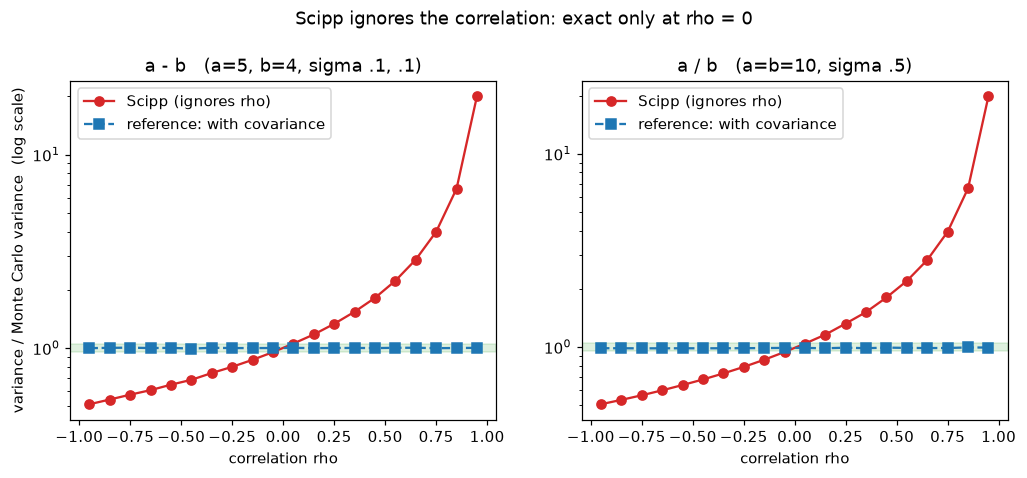

In [21]:
rng = np.random.default_rng(5)
rhos = np.linspace(-0.95, 0.95, 20)
panels = {
    'a - b   (a=5, b=4, sigma .1, .1)': (sub, (5.0, 4.0), (0.1, 0.1)),
    'a / b   (a=b=10, sigma .5)': (div, (10.0, 10.0), (0.5, 0.5)),
}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (title, (function, mean, sigma)) in zip(axes, panels.items()):
    scipp_ratio, reference_ratio = [], []
    for rho in rhos:
        covariance = np.array([
            [sigma[0] ** 2, rho * sigma[0] * sigma[1]],
            [rho * sigma[0] * sigma[1], sigma[1] ** 2],
        ])
        samples = rng.multivariate_normal(mean, covariance, 400_000)
        truth = monte_carlo_variance(function, samples[:, 0], samples[:, 1])
        scipp_value = scipp_variance(
            function, scipp_scalar(mean[0], sigma[0]), scipp_scalar(mean[1], sigma[1])
        )
        scipp_ratio.append(scipp_value / truth)
        reference_ratio.append(full_covariance_variance(function, mean, covariance) / truth)
    ax.axhspan(1 - HOLDS_WITHIN, 1 + HOLDS_WITHIN, color='tab:green', alpha=0.15)
    ax.plot(rhos, scipp_ratio, 'o-', color='tab:red', label='Scipp (ignores rho)')
    ax.plot(rhos, reference_ratio, 's--', color='tab:blue', label='reference: with covariance')
    ax.set_yscale('log')
    ax.set_xlabel('correlation rho')
    ax.set_title(title)
    ax.legend()
axes[0].set_ylabel('variance / Monte Carlo variance  (log scale)')
fig.suptitle('Scipp ignores the correlation: exact only at rho = 0', y=1.04)
plt.show()

## 2B. `es.math` against Scipp, with correlation

**Secondary comparison.** Neither library uses $\rho$, so the variance does not depend on it and the
comparison needs one row per function. The `Parameter` operators and `es.math` against Scipp:

In [22]:
first_by_function = {}
for r in part2:
    first_by_function.setdefault(r['key'], r)

table(
    [
        (
            r['case'].rsplit('   rho=', 1)[0],
            number(r['scipp']),
            number(r['es']),
            ratio_to_scipp(r['es'], r['scipp']),
            agreement(r['es'], r['scipp']),
        )
        for r in first_by_function.values()
    ],
    ['case', 'Scipp', 'es.math / Parameter', 'es/Scipp', 'result'],
)

case,Scipp,es.math / Parameter,es/Scipp,result
"a - b a=5, b=4 sigma .1, .1",0.02,0.02,1.000000,agree
"a + b a=5, b=4 sigma .1, .1",0.02,0.02,1.000000,agree
"a + b sigma .1, .001 (b negligible)",0.01,0.01,1.000000,agree
a / b a=b=10 sigma .5,0.005,0.005,1.000000,agree
a * b a=b=1 sigma .5 (large sigma),0.5,0.5,1.000000,agree
"arctan2(a, b) a=1, b=2 sigma .1, .1",n/a,0.002,n/a,Scipp n/a
"arctan2(a, b) a=0, b=2 sigma .05 (d/db = 0)",n/a,0.000625,n/a,Scipp n/a


**Reading the table.** The `Parameter` operators return Scipp's variance exactly: they are built on
it. `arctan2` is the case where `es.math` goes beyond Scipp: it has no Scipp variance, and `es.math`
computes one from its own derivative, which also assumes independent inputs.

## 2C. All three together, with correlation

Scipp, `es.math` (or the `Parameter` operator), Monte Carlo and the labelled *reference*.

In [23]:
table(
    [
        (
            r['case'],
            number(r['scipp']),
            number(r['es']),
            number(r['mc']),
            number(r['reference']),
            ratio(r['scipp'], r['mc']),
            ratio(r['es'], r['mc']),
        )
        for r in part2
    ],
    ['case', 'Scipp', 'es.math', 'Monte Carlo', 'reference', 'Scipp/MC', 'es/MC'],
)

case,Scipp,es.math,Monte Carlo,reference,Scipp/MC,es/MC
"a - b a=5, b=4 sigma .1, .1 rho=+0.00",0.02,0.02,0.01998,0.02,1.001,1.001
"a - b a=5, b=4 sigma .1, .1 rho=+0.90",0.02,0.02,0.001999,0.002,10.003,10.003
"a - b a=5, b=4 sigma .1, .1 rho=-0.90",0.02,0.02,0.03799,0.038,0.526,0.526
"a + b a=5, b=4 sigma .1, .1 rho=+0.00",0.02,0.02,0.01997,0.02,1.001,1.001
"a + b a=5, b=4 sigma .1, .1 rho=-0.90",0.02,0.02,0.002001,0.002,9.995,9.995
"a + b sigma .1, .001 (b negligible) rho=+0.90",0.01,0.01,0.01016,0.01018,0.984,0.984
a / b a=b=10 sigma .5 rho=+0.95,0.005,0.005,0.000252,0.00025,19.844,19.844
a * b a=b=1 sigma .5 (large sigma) rho=-0.50,0.5,0.5,0.3286,0.25,1.522,1.522
"arctan2(a, b) a=1, b=2 sigma .1, .1 rho=+0.00",n/a,0.002,0.002002,0.002,n/a,0.999
"arctan2(a, b) a=1, b=2 sigma .1, .1 rho=-0.87",n/a,0.002,0.003377,0.003392,n/a,0.592


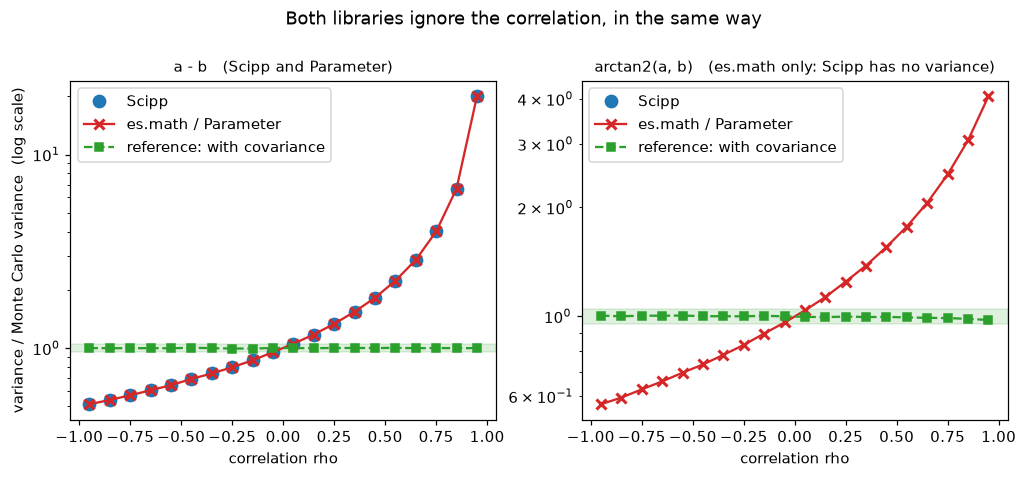

In [24]:
rng = np.random.default_rng(6)
rhos = np.linspace(-0.95, 0.95, 20)
panels = {
    'a - b   (Scipp and Parameter)': (sub, sub, sub, (5.0, 4.0), (0.1, 0.1)),
    'arctan2(a, b)   (es.math only: Scipp has no variance)': (
        scipp_atan2,
        m.arctan2,
        np.arctan2,
        (1.0, 2.0),
        (0.1, 0.1),
    ),
}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (title, (scipp_function, es_function, np_function, mean, sigma)) in zip(
    axes, panels.items()
):
    scipp_ratio, es_ratio, reference_ratio = [], [], []
    for rho in rhos:
        covariance = np.array([
            [sigma[0] ** 2, rho * sigma[0] * sigma[1]],
            [rho * sigma[0] * sigma[1], sigma[1] ** 2],
        ])
        samples = rng.multivariate_normal(mean, covariance, 400_000)
        truth = monte_carlo_variance(np_function, samples[:, 0], samples[:, 1])
        scipp_value = scipp_variance(
            scipp_function, scipp_scalar(mean[0], sigma[0]), scipp_scalar(mean[1], sigma[1])
        )
        es_value = es_variance(
            es_function, parameter(mean[0], sigma[0]), parameter(mean[1], sigma[1])
        )
        scipp_ratio.append(np.nan if scipp_value is None else scipp_value / truth)
        es_ratio.append(es_value / truth)
        reference_ratio.append(full_covariance_variance(np_function, mean, covariance) / truth)
    ax.axhspan(1 - HOLDS_WITHIN, 1 + HOLDS_WITHIN, color='tab:green', alpha=0.15)
    ax.plot(rhos, scipp_ratio, 'o', color='tab:blue', ms=8, label='Scipp')
    ax.plot(rhos, es_ratio, 'x-', color='tab:red', ms=7, mew=2, label='es.math / Parameter')
    ax.plot(
        rhos, reference_ratio, 's--', color='tab:green', ms=5, label='reference: with covariance'
    )
    ax.set_yscale('log')
    ax.set_xlabel('correlation rho')
    ax.set_title(title, fontsize=10)
    ax.legend()
axes[0].set_ylabel('variance / Monte Carlo variance  (log scale)')
fig.suptitle('Both libraries ignore the correlation, in the same way', y=1.04)
plt.show()

**Reading the table and figure.**

* The libraries coincide (blue circles under red crosses for `a - b`); `arctan2` has only the red
  line. Both libraries are wrong by the same factor, because both ignore $\rho$.
* The *reference* matches Monte Carlo to 0.2 % for `a - b` and `a + b`, to 1 % for `a / b` and to 2 %
  for `arctan2` (the rest is curvature), so the correlation is almost the whole error in those rows.
* **The `a * b` row is different**: with both $\sigma$ large it is wrong even with the covariance,
  because the second-order term $\sigma_a^2\sigma_b^2(1+\rho^2)$ is missing:
  $0.25 + 0.0625\times1.25 = 0.328$.
* `arctan2(0, 2)` holds although $\rho=0.9$: the derivative with respect to $b$ is zero there, so the cross term vanishes.

## What this means

1. **Scipp's first-order variance is trustworthy for small, independent errors.** It matched Monte
   Carlo to within 0.6 % in the small-$\sigma$ cases.
2. **`es.math` inherits Scipp's behaviour exactly** (1B, 2B). It differs only in coverage:
   `erf`, `erfc` and `arctan2` have a variance in `es.math` and none in Scipp.
3. **The single-input failure modes are well defined**: large $\sigma$, a zero derivative, and a
   pole. Scipp has no guard. `es.math` refuses a `tan` input within one $\sigma$ of a pole
   (and an `arctan2` point within one $\sigma$ of the origin), so an input $1.4\,\sigma$ from the pole is
   accepted, although 8 % of its samples cross the pole.
4. **Correlation is the larger practical risk.** Fit parameters are correlated by construction (slope
   and intercept come out near $\rho\approx-0.9$), and any function of two of them is wrong by a
   factor of 2 or more if the correlation is ignored. The covariance repairs the linear part exactly.
5. **Neither fix covers large $\sigma$ with products** (`a * b`): that needs second order.

## Questions for discussion

* Should the `es.math` docstrings state that the variance is Scipp's first-order variance, with the
  limits above (large $\sigma$, stationary points, poles)?
* Is one $\sigma$ the right distance for the guards of `tan` (pole) and `arctan2` (origin)? At
  $1.4\,\sigma$ from a pole the first-order variance is already meaningless; a margin of several
  $\sigma$ would refuse such inputs.
* Is it acceptable that Scipp, `Parameter` arithmetic and `es.math` ignore correlations stored by a
  fit? A separate branch (`feat/fit-correlations`) stores the correlation coefficients after a fit and
  uses $\mathbf g^{\mathsf T} C\,\mathbf g$; Part 2 is the argument for it.
* Do we want a second-order option for large relative errors, or is documenting the limit enough?

## Reproducing this notebook

Run all cells with the project's environment. Random seeds are fixed in every part. The only
inputs are the code on the checked-out branch (printed in the first cell), Scipp, NumPy and SciPy.